# Análisis Exploratorio de Datos (EDA) - **“Sistema predictivo de la intención declarada de estudiar en áreas de Informática / Tecnología / Programación / Ciencia de Datos según factores socioeducativos, actitudinales y de preferencias en alumnos argentinos de 16 a 18 años”**
## Autor: Mauricio Turdo
## Carrera: Tecnicatura Superior en Ciencia de Datos e Inteligencia Artificial

Fuente de Datos para Este proyecto Actitud de la juventud hacia las profesiones STEM  
https://www.argentina.gob.ar/sites/default/files/informe_preliminar_jovenes_stem.pdf

### Conjunto de datos

| Campo | Detalle |
| :--- | :--- |
| **Nombre** | Actitud de los jóvenes hacia las profesiones STEM |
| **Organismo** | IDES-KNAC para el MINCyT |
| **Período de relevamiento** | Del 17 de julio al 19 de agosto de 2023 |
| **Fuente** | Portal oficial `argentina.gob.ar` (formato CSV)|
| **Formato** | Archivo tabular (CSV) |
| **Dimensiones iniciales** | 2.891 registros y 217 columnas |
| **Licencia** | Uso público sujeto a reconocimiento de autoría y comunicación previa por escrito |

### Contenido del Documento
1. Introducción y Objetivos
2. Carga del Dataset y Verificación
3. Delimitación Poblacional   
4. Definición de la Variable Objetivo   
5. Análisis de Variables y Depuración
6. Partición de Datos
7. Diagnóstico y Tratamiento de Valores Nulos
8. Esquema de Transformaciones y Pipeline   
9. Análisis y Ranking de Correlación
10. Exportación del Dataset Filtrado






## 1. Introducción y Objetivos
El propósito de este notebook es realizar un Análisis Exploratorio de Datos (EDA) riguroso sobre el dataset seleccionado, documentando cada etapa del preprocesamiento, detección de anomalías y análisis estadístico para fundamentar las decisiones tomadas de cara a futuras etapas de modelado.





In [67]:
# 1. Librerías de manipulación de datos y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 2. Carga del Dataset y verificacion

In [68]:
# Cargar el dataset
df = pd.read_csv('/content/estudio_stem_usuaria.csv')

print("--- DIMENSIONES DEL DATASET ---")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}\n")

# Verificación de calidad y consistencia
print("--- VERIFICACIÓN DE CALIDAD DE DATOS ---")
print(f"Registros duplicados totales: {df.duplicated().sum()}")
print(f"IDs únicos en el dataset: {df['ID'].nunique()} (Total filas: {len(df)})")
print(f"Valores nulos globales en la tabla original: {df.isnull().sum().sum()}")

print("\n--- PRIMEROS REGISTROS ---")
display(df.head())
print("\n--- INFORMACION DEL DATASET ---")
df.info()

--- DIMENSIONES DEL DATASET ---
Filas: 2891 | Columnas: 217

--- VERIFICACIÓN DE CALIDAD DE DATOS ---
Registros duplicados totales: 0
IDs únicos en el dataset: 2891 (Total filas: 2891)
Valores nulos globales en la tabla original: 219845

--- PRIMEROS REGISTROS ---


,ID,F1.Edad,REGION,F4.SEXO,P2_a,P2_b,P2_c,P2_d,P2_e,P2_f,...,P33a,P33b,P33c,P35,P36,P37,P38,P39,P39a,POND_SIN_ELEVAR
0,4,18,2,1,4,3,2,3,1,1,...,3,2,1,1,3.0,3.0,2,1,1.0,1.763319
1,6,16,5,1,2,4,4,4,3,2,...,7,1,4,1,3.0,3.0,1,2,NaN,0.505173
2,19,16,1,1,2,3,3,2,2,2,...,4,2,2,2,2.0,5.0,2,2,NaN,0.330690
3,32,18,5,1,2,3,4,2,2,2,...,5,3,2,2,5.0,4.0,3,2,NaN,0.505173
4,36,17,1,1,1,3,2,2,3,3,...,5,3,2,2,5.0,4.0,3,2,NaN,0.330690



--- INFORMACION DEL DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2891 entries, 0 to 2890
Columns: 217 entries, ID to POND_SIN_ELEVAR
dtypes: float64(103), int64(114)
memory usage: 4.8 MB


### Descripción de la Carga de Datos

* Dimensiones de la Tabla: 2.891 observaciones y 217 variables.
* Tipos de Datos:
  * 114 variables de tipo entero (`int64`).
  * 103 variables de tipo flotante (`float64`).
* Uso de Memoria: 4.8 MB.


## 3. Delimitación de la población de estudio

### Delimitación de la Población de Estudio

Para aislar al público objetivo de interés, se aplicó un filtro estricto sobre la variable **P12** (nivel educativo cursado). El cuestionario original establece que las preguntas del bloque de intenciones vocacionales (bloque **P13**) se aplicaron exclusivamente a quienes cursaban el secundario (`P12 = 1` o `2`).

Al aplicar este filtro y analizar la distribución de respuestas en la pregunta clave `P13_12` ("No sé aún"), se obtuvo el siguiente desglose de los 505 registros excluidos de la muestra base:
* **408 casos** correspondieron a estudiantes indecisos que marcaron exclusivamente la opción "No sé todavía" (`P13_12`).
* **68 casos** correspondieron a respuestas negativas explícitas.
* **29 casos** constituyeron registros sin respuesta (valores nulos).

Esta depuración garantiza trabajar con un conjunto de datos homogéneo y con una intención vocacional definida, reduciendo el ruido analítico antes de definir la variable objetivo ($y$).

La aplicación del filtro reduce el conjunto original de 2.891 observaciones a 2.386 registros.

**Justificación metodológica:** al tratarse de un problema de aprendizaje supervisado, es necesario contar con una variable objetivo conocida para cada observación utilizada en el entrenamiento y la evaluación del modelo. Cabe destacar que la pregunta P13 solo se aplicó a quienes respondieron `P12 = 1` o `2`. De los **505 casos excluidos** del análisis principal, se identifican con precisión **408 indecisos ("No sé todavía")**, **68 respuestas negativas ("No")** y **29 sin respuesta**.

**Alcance y limitaciones:** el modelo se desarrollará exclusivamente sobre las observaciones que cumplen el criterio de selección establecido mediante `P12`. Por lo tanto, sus resultados no deben generalizarse automáticamente al total de participantes de la encuesta. Las observaciones correspondientes a las categorías 3 y 4, así como aquellas sin respuesta en `P12`, quedan fuera del universo analizado.

In [69]:
# --- DELIMITACIÓN DE LA POBLACIÓN DE ESTUDIO ---

# 1. Verificar distribución original de P12
print("--- DISTRIBUCIÓN ORIGINAL DE P12 ---")
print(df['P12'].value_counts(dropna=False).sort_index())

# 2. Aplicar criterio de selección
df_filtrado = df[
    df['P12'].isin([1.0, 2.0])].copy()

# 3. Verificar dimensiones
print("\n--- RESULTADO DEL FILTRADO ---")
print(f"Registros originales: {len(df)}")
print(f"Registros seleccionados: {len(df_filtrado)}")
print(f"Registros excluidos: {len(df) - len(df_filtrado)}")

# 4. Verificar respuestas de la variable objetivo original
print("\n--- VERIFICACIÓN DE P13_9 ---")
print(df_filtrado['P13_9'].value_counts(dropna=False))

print("\nValores faltantes en P13_9:",
    df_filtrado['P13_9'].isna().sum())

# 5. Validaciones de consistencia
assert len(df_filtrado) == 2386, ("La cantidad de registros seleccionados no coincide "
    "con el resultado esperado.")
assert df_filtrado['P13_9'].notna().all(), (
    "Existen registros sin respuesta en P13_9.")

print("\nValidaciones superadas: población delimitada correctamente.")

--- DISTRIBUCIÓN ORIGINAL DE P12 ---
P12
1.0    2204
2.0     182
3.0      68
4.0     408
NaN      29
Name: count, dtype: int64

--- RESULTADO DEL FILTRADO ---
Registros originales: 2891
Registros seleccionados: 2386
Registros excluidos: 505

--- VERIFICACIÓN DE P13_9 ---
P13_9
2.0    2027
1.0     359
Name: count, dtype: int64

Valores faltantes en P13_9: 0

Validaciones superadas: población delimitada correctamente.


#### Análisis de los registros excluidos
Se comparan características demográficas (sexo) entre los 2.386 registros retenidos y los 505 excluidos por el filtro de la variable P12 - **"¿Pensás continuar tus estudios al terminar la escuela?"**.

--- COMPARACIÓN PROPORCIONAL: INCLUIDOS VS EXCLUIDOS ---

Distribución por Sexo (F4.SEXO) [1: Mujer, 2: Varón, etc.]:
excluido      False      True 
F4.SEXO                       
1         60.771165  36.831683
2         37.678122  61.782178
3          1.550712   1.386139


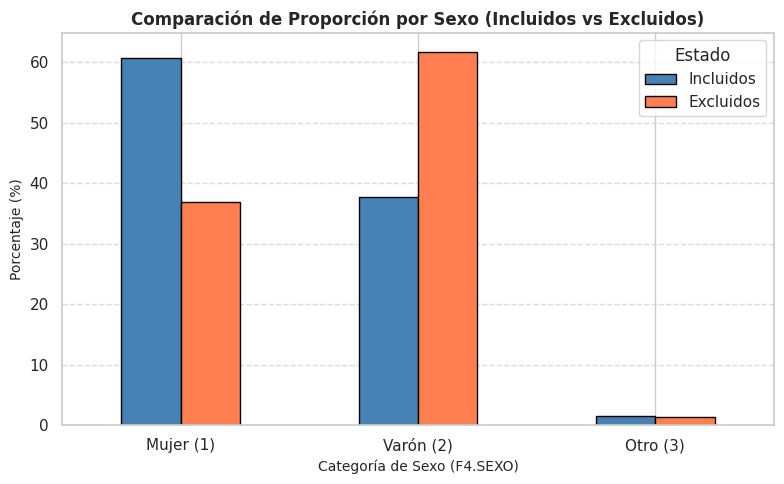

In [70]:
# --- ANÁLISIS DE LOS 505 REGISTROS EXCLUIDOS POR P12 ---
# Distribución de SEXO entre incluidos y excluidos

# Marcamos quiénes fueron excluidos del df original
df_analisis_excluidos = df.copy()
df_analisis_excluidos['excluido'] = ~df_analisis_excluidos.index.isin(df_filtrado.index)

print("--- COMPARACIÓN PROPORCIONAL: INCLUIDOS VS EXCLUIDOS ---")
print("\nDistribución por Sexo (F4.SEXO) [1: Mujer, 2: Varón, etc.]:")
print(pd.crosstab(df_analisis_excluidos['F4.SEXO'], df_analisis_excluidos['excluido'], normalize='columns') * 100)

# --- GRÁFICO COMPARATIVO DE EXCLUIDOS VS INCLUIDOS POR SEXO ---

fig, ax = plt.subplots(figsize=(8, 5))

# Calcular proporciones porcentuales
cross_sexo = pd.crosstab(df_analisis_excluidos['F4.SEXO'], df_analisis_excluidos['excluido'], normalize='columns') * 100
cross_sexo.columns = ['Incluidos', 'Excluidos']

# Generar gráfico de barras
cross_sexo.plot(kind='bar', ax=ax, color=['steelblue', 'coral'], edgecolor='black')

ax.set_title('Comparación de Proporción por Sexo (Incluidos vs Excluidos)', fontsize=12, fontweight='bold')
ax.set_xlabel('Categoría de Sexo (F4.SEXO)', fontsize=10)
ax.set_ylabel('Porcentaje (%)', fontsize=10)
ax.set_xticklabels(['Mujer (1)', 'Varón (2)', 'Otro (3)'], rotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Estado')

plt.tight_layout()
plt.show()

#### Análisis de impacto de los registros excluidos
Se evaluó si la exclusión de los 505 registros derivada del filtro poblacional (variable P12) genera algún sesgo sistemático en la muestra analizada:
- **Distribución por Sexo:** Se observa una variación en la proporción de sexos; el grupo excluido presenta una mayor concentración de la categoría 2 en comparación con el conjunto de datos retenido. Este hallazgo metodológico documenta que los resultados posteriores estarán condicionados por esta delimitación poblacional específica.

El análisis permite verificar si la exclusión introduce algún sesgo sistemático sobre determinados grupos poblacionales.

### Resultados de la delimitación poblacional

Luego de aplicar el criterio de selección sobre `P12`, se obtuvieron los siguientes resultados:

- **Dataset original:** 2.891 observaciones.
- **Registros seleccionados:** 2.386 observaciones.
- **Registros excluidos:** 505 observaciones.
- **Criterio aplicado:** conservar los registros con `P12 = 1` o `P12 = 2`.
- **Disponibilidad de la variable objetivo:** los registros seleccionados cuentan con respuestas válidas en `P13_9`.

La selección representa aproximadamente el 82,53 % del conjunto de datos original.

Se mantiene esta delimitación para asegurar que las observaciones utilizadas en el modelo cuenten con información disponible para definir la variable objetivo.

Los resultados del futuro modelo estarán condicionados por este criterio de selección y no representarán necesariamente a todos los participantes de la encuesta.

### 4. Definición de la variable objetivo

La variable objetivo ($y$) representa la intención declarada de estudiar una carrera vinculada con Informática, Tecnología, Programación o Ciencia de Datos.

Se construye a partir de la opción `P13_9` de la pregunta P13:
* **$y = 1$**: el encuestado seleccionó expresamente Informática, Tecnología, Programación o Ciencia de Datos.
* **$y = 0$**: el encuestado **no seleccionó dicha opción** (lo cual no implica una respuesta negativa explícita a la tecnología, sino que puede haber optado por otras áreas de estudio o ninguna de las anteriores).

**Tratamiento de las respuestas de incertidumbre:** Se identificaron **267 registros** que respondieron específicamente la opción de indecisión ("No sé aún", `P13_12`). Dado que el objetivo es modelar una elección concreta hacia estas disciplinas, estos casos se excluyen del conjunto utilizado para el entrenamiento y validación del modelo principal, evitando así sesgos por respuestas ambiguas.

In [71]:
# --- DEFINICIÓN Y LIMPIEZA DE LA VARIABLE OBJETIVO ---

# 1. Identificar las respuestas de incertidumbre
print("Distribución original de P13_12:")
print(df_filtrado['P13_12'].value_counts(dropna=False))

# 2. Excluir las respuestas "No sé aún"
# Según la codificación identificada en el notebook: P13_12 = 1
cantidad_incertidumbre = (df_filtrado['P13_12'] == 1).sum()

df_filtrado = df_filtrado[df_filtrado['P13_12'] != 1].copy()

# 3. Verificar que la variable objetivo tenga respuestas válidas
print("\nRegistros excluidos por incertidumbre:",cantidad_incertidumbre)

print("\nValores de P13_9 después del filtrado:")
print(df_filtrado['P13_9'].value_counts(dropna=False))

# 4. Crear la variable objetivo binaria
df_filtrado['y'] = (df_filtrado['P13_9'] == 1).astype(int)

# 5. Distribución de clases
print("\n--- DISTRIBUCIÓN DE LA VARIABLE OBJETIVO ---")

distribucion = df_filtrado['y'].value_counts().sort_index()
print(distribucion.rename({
    0: 'No (y=0)',
    1: 'Sí (y=1)'}))

# 6. Calcular prevalencia simple
prev_simple = df_filtrado['y'].mean() * 100
print(f"\nPrevalencia positiva sin ponderar: {prev_simple:.2f}%")

# 7. Calcular prevalencia ponderada, si corresponde
if 'POND_SIN_ELEVAR' in df_filtrado.columns:
    prev_ponderada = np.average(
        df_filtrado['y'],
        weights=df_filtrado['POND_SIN_ELEVAR']) * 100

    print(f"Prevalencia positiva ponderada: "f"{prev_ponderada:.2f}%")

print("\nTotal de registros para el modelado:",len(df_filtrado))


Distribución original de P13_12:
P13_12
2.0    2119
1.0     267
Name: count, dtype: int64

Registros excluidos por incertidumbre: 267

Valores de P13_9 después del filtrado:
P13_9
2.0    1760
1.0     359
Name: count, dtype: int64

--- DISTRIBUCIÓN DE LA VARIABLE OBJETIVO ---
y
No (y=0)    1760
Sí (y=1)     359
Name: count, dtype: int64

Prevalencia positiva sin ponderar: 16.94%
Prevalencia positiva ponderada: 19.75%

Total de registros para el modelado: 2119


### Análisis de la distribución de la variable objetivo

Luego del tratamiento de las respuestas de incertidumbre, el conjunto de datos utilizado para el modelado quedó conformado por **2.119 observaciones**.

La distribución de clases es la siguiente:

- **Clase negativa (y = 0):** 1.760 jóvenes que no seleccionaron Informática como su primera opción (lo que incluye tanto a quienes optaron por otras disciplinas STEM como a quienes manifestaron otras preferencias), evitando interpretarlo erróneamente como una respuesta negativa unívoca.
- **Clase positiva (y = 1):** 359 jóvenes que manifestaron intención de estudiar carreras vinculadas con Informática / Tecnología / Programación / Ciencia de Datos.

La prevalencia positiva sin ponderar representa aproximadamente el **16,94%** de los registros analizados.

Se observa un desequilibrio entre las clases, dado que la categoría negativa representa aproximadamente el 83,06 % y la positiva el 16,94%.

Esta distribución deberá considerarse durante la etapa de modelado y evaluación. Por este motivo, no será suficiente utilizar la exactitud (*accuracy*) como única métrica, sino que también se analizarán indicadores como *precision*, *recall*, *F1-score*, *ROC-AUC* y *balanced accuracy*.

Las estimaciones ponderadas se utilizarán como información descriptiva complementaria, diferenciándolas de las proporciones observadas directamente en la muestra.

## 5. Análisis exploratorio y selección de variables predictoras

Antes de construir el modelo de aprendizaje automático, se realizó una selección de variables con el objetivo de conservar aquellas que aportan información relevante para explicar la intención declarada de estudiar carreras vinculadas con Informática y Tecnología.

La selección se realizó considerando la naturaleza de las variables, su relación con la variable objetivo, la disponibilidad de información y la posibilidad de introducir fuga de información (*data leakage*).

### Criterios de exclusión aplicados

1. **Identificadores y ponderadores:** se excluyeron `ID` y `POND_SIN_ELEVAR`. El identificador no representa una característica explicativa del estudiante y el ponderador se reserva para análisis descriptivos de la muestra, evitando incorporarlo directamente como predictor.

2. **Variables utilizadas para definir la población y el objetivo:** se excluyeron `P12` y las variables `P13_1` a `P13_12`. P12 se utilizó para delimitar la población de estudio y P13_9 interviene directamente en la construcción de la variable objetivo. Incorporar estas variables como predictoras produciría fuga de información.

3. **Variables con riesgo de fuga de información:** se excluyeron las preguntas correspondientes a P15, P16 y P18, debido a que están relacionadas con decisiones o situaciones posteriores o condicionadas por la elección educativa que se busca predecir. Su incorporación podría revelar indirectamente información sobre la respuesta objetivo.

4. **Variables condicionales y de baja frecuencia:** se excluyeron `P39` y `P39a`, debido a que corresponden a preguntas aplicables a un subgrupo reducido de participantes y podrían aportar información poco representativa para el objetivo general del modelo.

5. **Variables con posible redundancia conceptual:** se excluyeron `P33b` y `P33c`, conservando `P33a` como indicador del total de integrantes del hogar. Esta decisión busca evitar incorporar simultáneamente medidas que representan dimensiones relacionadas. Se deberá respaldar con la definición de las variables del cuestionario.

### Se excluyo por vacíos estructurales y fuga de información

Se excluyeron del conjunto de variables predictoras las preguntas pertenecientes a los bloques **P15, P16 y P18** debido a dos razones clave:

1. **Vacíos estructurales condicionales:** Estas preguntas presentan un elevado porcentaje de valores nulos que no responden a errores de carga ni a omisiones aleatorias, sino a la propia lógica condicional del cuestionario (salto de preguntas). Solo fueron respondidas por aquellos encuestados que manifestaron previamente ciertas intenciones o condiciones específicas.

2. **Fuga de información (Data Leakage):** Al estar directamente condicionadas por la decisión educativa del estudiante, estas variables recopilan información posterior o simultánea a la elección de la carrera. Permitir que el modelo utilice estos datos como predictivos introduciría un sesgo de fuga de información, revelando indirectamente la variable objetivo y distorsionando la capacidad predictiva real del sistema sobre nuevos casos.
### Resultado esperado

Como resultado de este proceso se obtiene una matriz de variables predictoras (`X`) y una variable objetivo binaria (`y`), manteniendo separada la información utilizada para seleccionar la población y definir la respuesta que se desea predecir.

In [72]:
# --- TRATAMIENTO DE CÓDIGOS ESPECIALES ---

df_filtrado = df_filtrado.copy()

# 1. P5_d, P5_e y P5_f (Código 5: "No tengo la materia")
for letra in ['d', 'e', 'f']:
    columna = f'P5_{letra}'
    if columna in df_filtrado.columns:
        df_filtrado[f'no_tiene_{columna}'] = (df_filtrado[columna] == 5).astype(int)
        df_filtrado[columna] = df_filtrado[columna].replace(5, np.nan)

# 2. P6 y P7 (Código 6: "No tengo estas materias") -> Indicador no_tiene_*
for prefijo in ['P6', 'P7']:
    for letra in ['d', 'e', 'f']:
        columna = f'{prefijo}_{letra}'
        if columna in df_filtrado.columns:
            df_filtrado[f'no_tiene_{columna}'] = (df_filtrado[columna] == 6).astype(int)
            df_filtrado[columna] = df_filtrado[columna].replace(6, np.nan)

# 3. P36 y P37 (Código 6: "No sé") -> Indicador no_sabe_*
for columna in ['P36', 'P37']:
    if columna in df_filtrado.columns:
        df_filtrado[f'no_sabe_{columna}'] = (df_filtrado[columna] == 6).astype(int)
        df_filtrado[columna] = df_filtrado[columna].replace(6, np.nan)

# 4. P27: Código 99 define Ns/Nc -> pasa a NaN
if 'P27' in df_filtrado.columns:
    df_filtrado['P27'] = df_filtrado['P27'].replace(99, np.nan)

# 5. P38: Valores de 10 o más habitaciones pasan a NaN
if 'P38' in df_filtrado.columns:
    df_filtrado.loc[df_filtrado['P38'] >= 10, 'P38'] = np.nan

# 6. Definición de columnas a excluir (Fuga de información y metadatos)
columnas_a_excluir = ['ID', 'POND_SIN_ELEVAR', 'P12']
columnas_a_excluir += [f'P13_{i}' for i in range(1, 13)]

prefijos_excluidos = ('P15', 'P16', 'P18', 'P39', 'P33b', 'P33c')
fuga_columnas = [col for col in df_filtrado.columns if col.startswith(prefijos_excluidos)]
columnas_a_excluir += fuga_columnas
columnas_a_excluir = list(dict.fromkeys([col for col in columnas_a_excluir if col in df_filtrado.columns]))

# 7. Construcción de X e y
columnas_a_remover = columnas_a_excluir + ['y']
features_candidatas = [col for col in df_filtrado.columns if col not in columnas_a_remover]

X = df_filtrado[features_candidatas].copy()
y = df_filtrado['y'].copy()

print(f"Variables predictoras (X) creadas con éxito: {X.shape[1]} columnas.")
print(f"Registros listos para particionar: {len(X)}")

Variables predictoras (X) creadas con éxito: 127 columnas.
Registros listos para particionar: 2119


### Análisis de resultados de la depuración de variables

Luego de aplicar los criterios de selección y exclusión, se construyó una matriz de variables predictoras (`X`) y se mantuvo separada la variable objetivo (`y`).

Durante esta etapa se realizaron las siguientes operaciones:

- Exclusión de identificadores y ponderadores.
- Eliminación de las variables utilizadas para delimitar la población y construir la variable objetivo.
- Exclusión de variables con posible fuga de información.
- Eliminación de variables condicionales o conceptualmente redundantes, según los criterios definidos.
- Identificación y tratamiento de códigos especiales mediante indicadores binarios y conversión a valores faltantes cuando corresponde.

Se conservaron las observaciones válidas para el problema de clasificación binaria, manteniendo la correspondencia entre las variables predictoras y la variable objetivo.

La cantidad definitiva de variables predictoras se obtiene mediante la ejecución del código de depuración y se utilizará como base para las siguientes etapas de exploración y preprocesamiento.

Esta selección busca construir un conjunto de datos consistente, reducir información redundante y evitar que el modelo utilice variables que revelen directa o indirectamente la respuesta que se desea predecir.

## 6. Partición de Datos

In [73]:
from sklearn.model_selection import train_test_split

# Partición estratificada (80/20) sobre el dataset ya depurado y con códigos especiales tratados
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Entrenamiento (X_train): {X_train.shape}")
print(f"Evaluación (X_test): {X_test.shape}")

Entrenamiento (X_train): (1695, 127)
Evaluación (X_test): (424, 127)


## 7. Diagnóstico y Tratamiento de Valores Nulos


In [74]:
nulos_df = pd.DataFrame({
    'Cantidad_Nulos': X.isnull().sum(),
    'Porcentaje_Nulos': (X.isnull().mean() * 100).round(2)})

nulos_df = nulos_df[nulos_df['Cantidad_Nulos'] > 0].sort_values(by='Porcentaje_Nulos', ascending=False)

print(f"\n--- Resultado del Diagnóstico: Total de variables con valores nulos: {len(nulos_df)} ---")
print(nulos_df.to_string())



--- Resultado del Diagnóstico: Total de variables con valores nulos: 17 ---
      Cantidad_Nulos  Porcentaje_Nulos
P25             1746             82.40
P21             1272             60.03
P20             1272             60.03
P7_d             705             33.27
P6_d             605             28.55
P5_d             466             21.99
P7_e             441             20.81
P24              373             17.60
P6_e             329             15.53
P7_f             230             10.85
P5_e             199              9.39
P6_f             167              7.88
P5_f             116              5.47
P36              104              4.91
P37              104              4.91
P27               13              0.61
P38               12              0.57


### Diagnóstico de valores faltantes

Luego de aplicar los criterios de selección poblacional, definir la variable objetivo y realizar el tratamiento inicial de códigos especiales, el conjunto de datos quedó conformado por **2.119 registros y 127 variables predictoras**.

El diagnóstico de valores faltantes permitió identificar 17 variables con datos nulos.

Se destacan los siguientes casos:
* **P25**: presenta 1.746 valores faltantes (82,40 %). Dado este volumen crítico, **se decide su exclusión explícita del pipeline**, reduciendo la matriz de trabajo a 126 variables predictoras antes de la codificación.
* **P20 y P21**: presentan 1.272 valores faltantes cada una (60,03 %).
* **P5, P6 y P7**: contienen valores faltantes originados, en parte, por el tratamiento de códigos especiales de respuesta.
* **P24**: presenta 373 valores faltantes (17,60 %).
* **P36 y P37**: presentan 104 valores faltantes cada una (4,91 %), luego de transformar el código de incertidumbre en valor nulo.

Los valores faltantes no deben interpretarse automáticamente como errores de carga. Algunos pueden responder a la estructura condicional del cuestionario, es decir, preguntas que no correspondían a determinados encuestados.

### Criterio de tratamiento

Se propone conservar los registros y gestionar los valores faltantes mediante técnicas de imputación dentro del pipeline de preprocesamiento:

* **Variables numéricas y ordinales:** Imputación por la mediana y posterior estandarización.
* **Variables nominales:** Imputación mediante constante fija (`0`) que representa metodológicamente la categoría estructural "no corresponde", seguida de codificación *One-Hot*.
* **Variables binarias:** Imputación mediante la categoría más frecuente (moda).
* **Indicadores de códigos especiales (`no_tiene_*` / `no_sabe_*`):** Incorporación de indicadores binarios que marcan situaciones específicas (como no tener la materia en el colegio o no conocer el nivel educativo), permitiendo que el modelo conserve esa información patrón explícita.

Para evitar la fuga de información (*data leakage*), los parámetros de imputación se calcularán exclusivamente con los datos de entrenamiento (`X_train`) y luego se aplicarán al conjunto de prueba (`X_test`).

## 8. Esquema de Transformaciones y Pipeline

Para preparar las variables antes de aplicar el modelo de Regresión Logística, se diseñó un esquema de transformación mediante `ColumnTransformer` y subprocesos `Pipeline`.

| Tipo de variable | Ejemplos | Transformación | Fundamento |
| :--- | :--- | :--- | :--- |
| **Binarias** | P8, P9, P19, P22, P23, P26, P31, P32 | Recodificación 1/2 a 1/0 e imputación | Facilita la interpretación de las respuestas binarias. |
| **Ordinales** | P2, P3, P5, P6, P7, P36, P37 | Imputación por mediana y estandarización | Conserva el orden natural de las categorías. |
| **Nominales** | REGION, F4.SEXO, P4, P10, P11, P20, P21, P24, P27, P28, P35 | Imputación con constante 0 y `OneHotEncoder` | Evita asignar un orden artificial a categorías sin jerarquía. |
| **Numéricas** | F1.Edad, P33a, P38 | Imputación por mediana y estandarización | Permite trabajar con variables de distinta escala. |

**Prevención de fuga de datos (data leakage):** los parámetros de imputación, codificación y escalado se ajustan exclusivamente con `X_train`. Luego, las mismas transformaciones se aplican a `X_test`, sin volver a ajustarlas.

In [75]:
# --- ESQUEMA DE TRANSFORMACIONES Y PIPELINE ---
import re
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

X_train = X_train.copy()
X_test = X_test.copy()

for df_temp in [X_train, X_test]:
    if 'P25' in df_temp.columns:
        df_temp.drop(columns=['P25'], inplace=True)

# 1. CLASIFICACIÓN DE LAS VARIABLES
variables_ordinales = [
    col for col in X_train.columns
    if re.match(r'^P(2|3|5|6|7)_', col)
    or col in ['P36', 'P37']]

nombres_nominales = [
    'REGION', 'F4.SEXO', 'P4', 'P27', 'P28', 'P35','P20', 'P10_a', 'P10_b','P10_c',
    'P10_d', 'P10_e', 'P10_f', 'P10_g','P11_a', 'P11_b', 'P11_c', 'P11_d', 'P11_e','P24']

variables_nominales = [col for col in nombres_nominales if col in X_train.columns]
variables_numericas = [col for col in ['P33a', 'P38', 'F1.Edad'] if col in X_train.columns]

variables_binarias_originales = [
    col for col in X_train.columns
    if re.match(r'^P(8|9|22|19|31|32|23|26)(_|$)', col)]

# Nomenclatura no_tiene_* y no_sabe_*
variables_indicadoras = [col for col in X_train.columns
    if col.startswith('no_tiene_') or col.startswith('no_sabe_')]

variables_binarias = variables_binarias_originales + variables_indicadoras

# 2. VALIDACIÓN DE LA CLASIFICACIÓN (Excluimos 'P21' de la validación ya que se omite intencionalmente)
columnas_clasificadas = variables_ordinales + variables_nominales + variables_numericas + variables_binarias
sin_tratar = [col for col in X_train.columns if col not in columnas_clasificadas and col != 'P21']
duplicadas = [col for col in set(columnas_clasificadas) if columnas_clasificadas.count(col) > 1]

assert not sin_tratar, f"Hay variables sin clasificar: {sin_tratar}"
assert not duplicadas, f"Hay variables clasificadas más de una vez: {duplicadas}"
print("Clasificación de variables validada correctamente.")

# 3. RECODIFICACIÓN DE VARIABLES BINARIAS (1/2 a 1/0)
for col in variables_binarias_originales:
    X_train[col] = X_train[col].replace({1: 1, 2: 0})
    X_test[col] = X_test[col].replace({1: 1, 2: 0})

print("Variables binarias recodificadas.")

# 4. SUBPIPELINES DE TRANSFORMACIÓN
transformador_num_ord = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
    ('escalador', StandardScaler())])

transformador_nominal = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='constant', fill_value=0)),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

transformador_binario = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='most_frequent'))])

# 5. CONSTRUCCIÓN DEL COLUMNTRANSFORMER (Excluimos 'P21' para que el transformador la ignore por completo)
variables_nominales_filtradas = [col for col in variables_nominales if col != 'P21']

preprocesador = ColumnTransformer(transformers=[
        ('num_ord', transformador_num_ord, variables_ordinales + variables_numericas),
        ('nominales', transformador_nominal, variables_nominales_filtradas),
        ('binarias', transformador_binario, variables_binarias)],remainder='drop')

# 6. AJUSTE Y TRANSFORMACIÓN CON LIMPIEZA DE DUPLICADOS
X_train_prep_array = preprocesador.fit_transform(X_train)
X_test_prep_array = preprocesador.transform(X_test)

# Recuperar los nombres exactos de las columnas generadas
feature_names = preprocesador.get_feature_names_out()

# CONVERSIÓN A DATAFRAMES CONSERVANDO EL ÍNDICE ORIGINAL
X_train_prep = pd.DataFrame(X_train_prep_array, columns=feature_names, index=X_train.index)
X_test_prep = pd.DataFrame(X_test_prep_array, columns=feature_names, index=X_test.index)

# Eliminar columnas duplicadas por contenido idéntico basándonos en X_train_prep
mask_dups = ~X_train_prep.T.duplicated()
columnas_eliminadas = X_train_prep.columns[~mask_dups].tolist()

if columnas_eliminadas:
    print(f"Columnas duplicadas detectadas y eliminadas: {columnas_eliminadas}")
else:
    print("No se encontraron columnas duplicadas.")

# Aplicar la máscara de manera idéntica a train y test
X_train_prep = X_train_prep.loc[:, mask_dups]
X_test_prep = X_test_prep.loc[:, mask_dups]

# 7. RESULTADOS Y CONTROLES
print(f"\nDimensiones después de la transformación (X_train_prep): {X_train_prep.shape}")
print(f"Dimensiones después de la transformación (X_test_prep): {X_test_prep.shape}")
print("\nPreprocesamiento finalizado correctamente sin columnas duplicadas.")

Clasificación de variables validada correctamente.
Variables binarias recodificadas.
No se encontraron columnas duplicadas.

Dimensiones después de la transformación (X_train_prep): (1695, 208)
Dimensiones después de la transformación (X_test_prep): (424, 208)

Preprocesamiento finalizado correctamente sin columnas duplicadas.


El preprocesamiento se realizó sobre las **125 variables** predictoras que ingresan al pipeline (tras excluir `P25` por su $82,40\%$ de nulos y `P21`).

El desglose de las características transformadas es:
* **31 variables ordinales:** imputación por mediana y estandarización.
* **21 variables nominales:** imputación por constante fija (`0`, "no corresponde") y codificación One-Hot.
* **3 variables numéricas:** imputación por mediana y estandarización.
* **60 variables binarias originales:** recodificación de $1/2$ a $1/0$ e imputación por moda.
* **10 indicadores de códigos especiales:** incorporación de flags binarias (`no_tiene_*` y `no_sabe_*`) para preservar patrones específicos de omisión estructural o incertidumbre.

Como resultado de la codificación One-Hot, la limpieza de columnas duplicadas y la integración de las transformaciones, la matriz predictora final quedó conformada por **208 columnas**.

La división de los datos produjo:
* **Entrenamiento:** 1.695 registros.
* **Prueba:** 424 registros.

Se evitó la fuga de información (*data leakage*) garantizando que el ajuste de todos los transformadores se realizara exclusivamente sobre el conjunto de entrenamiento. Posteriormente, las mismas transformaciones se aplicaron de forma idéntica sobre el conjunto de prueba.

## 9. Análisis y Ranking de Correlación


--- MAYORES CORRELACIONES CON LA VARIABLE OBJETIVO ---

Diez mayores correlaciones positivas:


,y
num_ord__P3_d,0.3916
num_ord__P5_d,0.3175
binarias__P8_3_f,0.2608
nominales__F4.SEXO_2.0,0.2579
nominales__P27_4.0,0.2477
nominales__P11_a_1.0,0.2429
nominales__P11_d_4.0,0.2051
binarias__P22_3,0.1765
num_ord__P7_d,0.1740
num_ord__P3_b,0.1673



Diez mayores correlaciones negativas:


,y
nominales__F4.SEXO_1.0,-0.2501
nominales__P11_d_3.0,-0.2409
nominales__P11_a_3.0,-0.1931
binarias__P8_3_e,-0.1046
nominales__P20_0.0,-0.1042
nominales__P11_e_3.0,-0.0933
binarias__P8_3_h,-0.0883
binarias__P9_3_g,-0.0861
binarias__P8_2_f,-0.0850
num_ord__P5_e,-0.0772


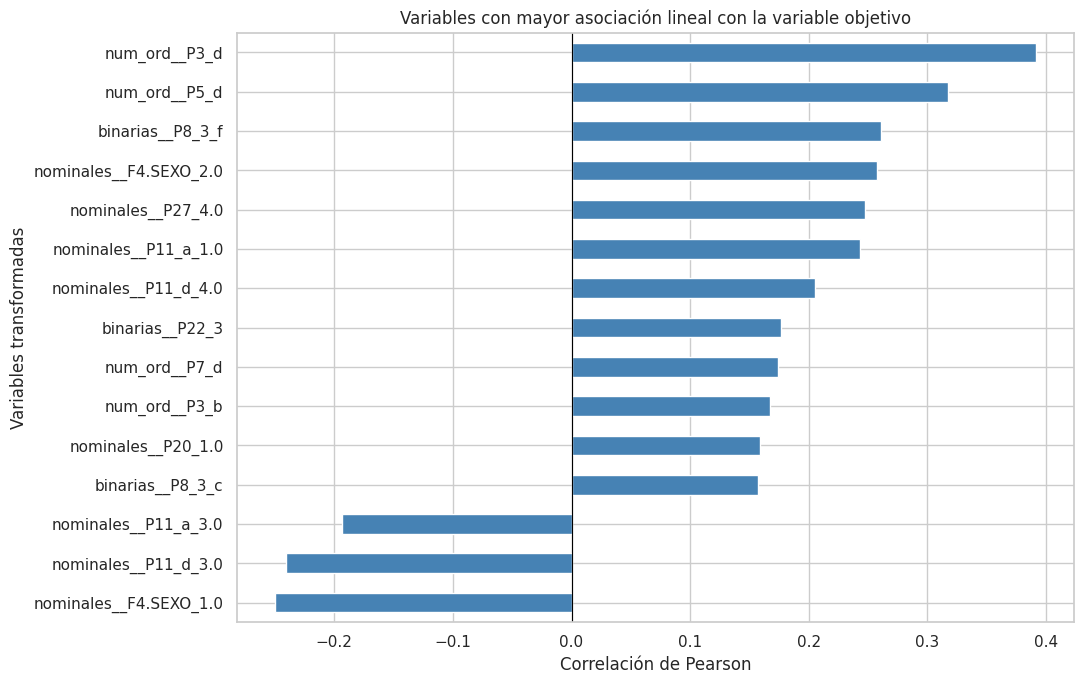


Nota: las correlaciones muestran asociaciones estadísticas, no implican causalidad.


In [76]:
# 1. Recuperar los nombres de las variables transformadas
nombres_variables = preprocesador.get_feature_names_out()

# 2. Como X_train_prep ya fue creado con index=X_train.index,
# se alinea de forma nativa y perfecta con y_train
df_corr = X_train_prep.copy()

# 3. Incorporar la variable objetivo asegurando la alineación por índice
df_corr['y'] = y_train

# 4. Calcular correlaciones de Pearson
matriz_corr = df_corr.corr()

correlacion_con_y = (matriz_corr['y'].drop('y').dropna())

# 5. Mostrar las variables con mayor asociación positiva y negativa
print("--- MAYORES CORRELACIONES CON LA VARIABLE OBJETIVO ---")

top_positivas = correlacion_con_y.sort_values(ascending=False).head(10)
top_negativas = correlacion_con_y.sort_values(ascending=True).head(10)

print("\nDiez mayores correlaciones positivas:")
display(top_positivas.round(4))
print("\nDiez mayores correlaciones negativas:")
display(top_negativas.round(4))

# 6. Gráfico de las 15 variables con mayor correlación absoluta
top_absolutas = (correlacion_con_y.abs().sort_values(ascending=False)
    .head(15).index)

datos_grafico = correlacion_con_y.loc[top_absolutas].sort_values()
plt.figure(figsize=(11, 7))
datos_grafico.plot(kind='barh', color='steelblue')

plt.title('Variables con mayor asociación lineal con la variable objetivo')
plt.xlabel('Correlación de Pearson')
plt.ylabel('Variables transformadas')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print("\nNota: las correlaciones muestran asociaciones estadísticas, no implican causalidad.")

### Análisis y Ranking de Correlación

El análisis de correlación lineal (Pearson) entre las variables transformadas y la variable objetivo muestra las asociaciones estadísticas más relevantes dentro del conjunto de entrenamiento:

* **Correlaciones positivas destacadas:** Las asociaciones directas más altas corresponden a **`num_ord__P3_d`** ($r = 0,39$) y **`num_ord__P5_d`** ($r = 0,32$), seguidas por **`binarias__P8_3_f`**, **`nominales__F4.SEXO_2.0`** (varón) y **`nominales__P27_4.0`** (orientación en Informática), además de **`nominales__P11_a_1.0`** y **`nominales__P11_d_4.0`**.
* **Correlaciones negativas destacadas:** Atributos como **`nominales__F4.SEXO_1.0`** ($r = -0,25$), **`nominales__P11_d_3.0`** y **`nominales__P11_a_3.0`** muestran las asociaciones inversas más marcadas.
* **Advertencia metodológica sobre variables próximas al objetivo:** Se destaca que las variables con mayor poder de asociación (**`num_ord__P3_d`**, **`nominales__P27_4.0`** y el grupo **`nominales__P11_*`**) se encuentran conceptualmente e informativamente muy cerca de la variable objetivo. Por lo tanto, **no deben interpretarse estrictamente como factores explicativos o causales externos**, ya que su alto valor responde a una gran proximidad estructural con lo que se intenta predecir (riesgo de alta redundancia o fuga de datos), limitando su rol como "causas" directas del fenómeno.


## 10. Exportación del Dataset Filtrado   


In [77]:
# --- EXPORTACIÓN DEL DATASET FILTRADO Y METADATOS ---
df_resultado_final = X.copy()
df_resultado_final['ID'] = df['ID'].loc[X.index]
df_resultado_final['POND_SIN_ELEVAR'] = df['POND_SIN_ELEVAR'].loc[X.index]
df_resultado_final['y'] = y.loc[X.index]

# Exportar a CSV
nombre_archivo = 'dataset_filtrado_y_metadatos.csv'
df_resultado_final.to_csv(nombre_archivo, index=False, encoding='utf-8')
print(f"✅ Dataset filtrado con metadatos exportado con éxito: {nombre_archivo}")

from google.colab import files
files.download(nombre_archivo)

✅ Dataset filtrado con metadatos exportado con éxito: dataset_filtrado_y_metadatos.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>